# Supply Chain & Inventory Optimization - Exploratory Data Analysis

> **SYNTHETIC DATA NOTICE** - every table in this project was generated by `scripts/generate_data.py` (seed 42) for a
> *fictional* Indian distributor (INR, 6 warehouses, 400 products, 40 suppliers, Jan 2024 - Sep 2026). Patterns such as chronic
> stockouts, slow suppliers and obsolete stock were embedded on purpose so the analysis has something to find
> (`data/embedded_patterns_answer_key.csv`). No real company, customer or supplier is represented.

**Business questions**
1. Which products frequently go out of stock?
2. Which warehouse has the highest inventory?
3. Which suppliers have longer delivery times?
4. Which products have high demand?
5. Where is excess inventory accumulating?
6. How can we reduce inventory holding costs?
7. Which products need restocking?

**Flow of this notebook:** load raw + processed data -> data quality (missing values, duplicates, outliers, cleaning log) ->
EDA (sales, inventory, seasonality) -> ABC / XYZ -> stockout & overstock -> supplier performance -> holding cost ->
reorder recommendations -> run every SQL query in `sql/03_analysis_queries.sql` against the DuckDB warehouse.

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, IMG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "images"
IMG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

# validated categorical palette (fixed order) + one sequential hue
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, INK, MUTED = "#2a78d6", "#1a1a19", "#6b6a63"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2})
inr_cr = mtick.FuncFormatter(lambda v, _: f"{v/1e7:,.1f} Cr")
def save(fig, name):
    fig.tight_layout(); fig.savefig(IMG / name, dpi=130, bbox_inches="tight"); plt.show()
print("project root:", ROOT.name)

project root: Supply_Chain_Inventory_Optimization


## 1. Load raw and processed data

In [2]:
TABLES = ["products", "suppliers", "customers", "warehouses", "sales", "purchases", "inventory"]
raw = {t: pd.read_csv(RAW / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
proc = {t: pd.read_csv(PROC / f"{t}.csv") for t in TABLES}
pd.DataFrame({"raw_rows": {t: len(raw[t]) for t in TABLES}, "processed_rows": {t: len(proc[t]) for t in TABLES},
              "columns": {t: proc[t].shape[1] for t in TABLES}}).assign(removed=lambda d: d.raw_rows - d.processed_rows)

,raw_rows,processed_rows,columns,removed
products,405,400,10,5
suppliers,42,40,6,2
customers,2025,2001,6,24
warehouses,6,6,7,0
sales,153199,152291,12,908
purchases,22870,22750,11,120
inventory,343600,343200,5,400


## 2. Data quality: missing values, duplicates, outliers

In [3]:
def blanks(df):
    return df.apply(lambda c: c.astype(str).str.strip().isin(["", "nan", "NaN", "NULL", "null", "N/A", "-"]).sum())
miss = pd.concat({t: blanks(raw[t]) for t in TABLES}).rename("raw_blank_cells").reset_index()
miss.columns = ["table", "column", "raw_blank_cells"]
miss = miss[miss.raw_blank_cells > 0]
miss["processed_nulls"] = [proc[t][c].isna().sum() if c in proc[t] else None for t, c in zip(miss.table, miss.column)]
miss.sort_values("raw_blank_cells", ascending=False).head(15)

,table,column,raw_blank_cells,processed_nulls
38,sales,Delivery_Date,12043,11968
37,sales,Ship_Date,11419,11348
32,sales,Customer_ID,151,0
20,customers,State,16,0
4,products,Unit_Cost,4,0


In [4]:
keys = {"products": "Product_ID", "suppliers": "Supplier_ID", "customers": "Customer_ID", "warehouses": "Warehouse_ID",
        "sales": "Sales_ID", "purchases": "Purchase_ID", "inventory": ["Snapshot_Date", "Product_ID", "Warehouse_ID"]}
pd.DataFrame({t: {"raw_exact_dupes": raw[t].duplicated().sum(),
                  "raw_key_dupes": raw[t].duplicated(subset=keys[t]).sum(),
                  "processed_key_dupes": proc[t].duplicated(subset=keys[t]).sum()} for t in TABLES}).T

,raw_exact_dupes,raw_key_dupes,processed_key_dupes
products,5,5,0
suppliers,2,2,0
customers,25,25,0
warehouses,0,0,0
sales,900,900,0
purchases,120,120,0
inventory,400,400,0


,min,median,max,outliers_3xIQR
Quantity,1.00,6.00,400.00,9881
Unit_Price,28.03,533.18,29521.72,10436
Discount,0.02,0.07,0.21,0


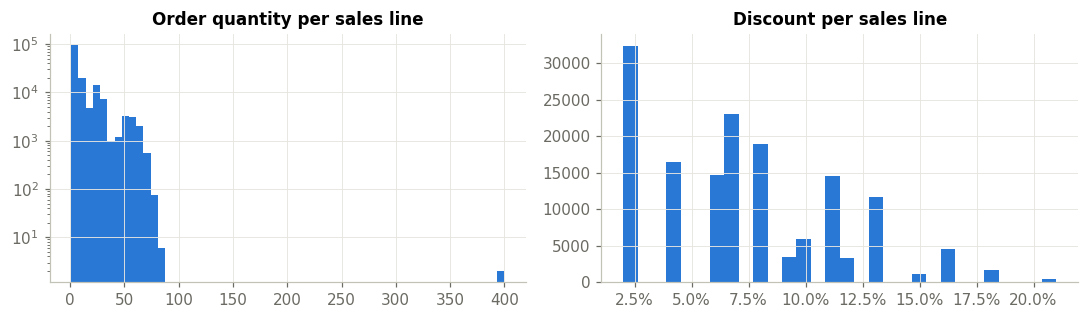

In [5]:
s = proc["sales"]
num = s[["Quantity", "Unit_Price", "Discount"]]
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
out = ((num < q1 - 3 * iqr) | (num > q3 + 3 * iqr)).sum()
display(pd.DataFrame({"min": num.min(), "median": num.median(), "max": num.max(), "outliers_3xIQR": out}))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(s.Quantity, bins=60, color=BLUE); ax[0].set_title("Order quantity per sales line"); ax[0].set_yscale("log")
ax[1].hist(s.Discount, bins=30, color=BLUE); ax[1].set_title("Discount per sales line"); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
save(fig, "01_outliers.png")

Large bulk orders (distributor / modern-trade customers) are genuine business outliers and are **kept** (logged as informational);
impossible values - negative quantities (sign errors), x100 keying errors on delivered lines, purchase unit costs > 10x the
product's median - were fixed in `src/data_cleaning.py`. Every rule and the rows it
touched is recorded in the cleaning log below.

In [6]:
log = pd.read_csv(PROC / "data_quality_log.csv")
print(f"{len(log)} cleaning checks, {log.Rows_Affected.sum():,} rows/cells affected")
log.sort_values("Rows_Affected", ascending=False).head(20)

56 cleaning checks, 60,549 rows/cells affected


,Table,Issue,Rows_Affected,Action
23,sales,"Mixed date formats in Order_Date (DD/MM/YYYY, ...",12150,Parsed explicitly to ISO date
24,sales,"Mixed date formats in Ship_Date (DD/MM/YYYY, D...",11399,Parsed explicitly to ISO date
25,sales,Mixed date formats in Delivery_Date (DD/MM/YYY...,11227,Parsed explicitly to ISO date
27,sales,Quantity above IQR fence (47) - informational,9060,Reviewed; only rule below changes data
21,sales,Inconsistent casing in Order_Status,3219,Mapped to most frequent spelling
20,sales,Leading/trailing/double spaces in text,3003,Trimmed and collapsed whitespace
37,purchases,"Mixed date formats in PO_Date (DD/MM/YYYY, DD-...",1868,Parsed explicitly to ISO date
38,purchases,Mixed date formats in Expected_Delivery_Date (...,1841,Parsed explicitly to ISO date
39,purchases,Mixed date formats in Actual_Delivery_Date (DD...,1738,Parsed explicitly to ISO date
32,sales,'NA' Discount,900,Imputed with customer-segment median


## 3. Build the analysis frame (DuckDB warehouse)

In [7]:
DB = ROOT / "warehouse" / "supply_chain.duckdb"
if not DB.exists():
    import subprocess, sys
    subprocess.run([sys.executable, str(ROOT / "scripts" / "build_warehouse.py")], check=True, capture_output=True)
con = duckdb.connect(str(DB), read_only=True)
q = lambda sql: con.execute(sql).df()
q("SELECT table_name, estimated_size AS approx_rows FROM duckdb_tables() ORDER BY table_name")

,table_name,approx_rows
0,config,1
1,dim_customer,2001
2,dim_date,1096
3,dim_product,400
4,dim_supplier,40
5,dim_warehouse,6
6,fact_inventory_snapshot,343200
7,fact_purchases,22750
8,fact_sales,152291


## 4. Sales trend and seasonality

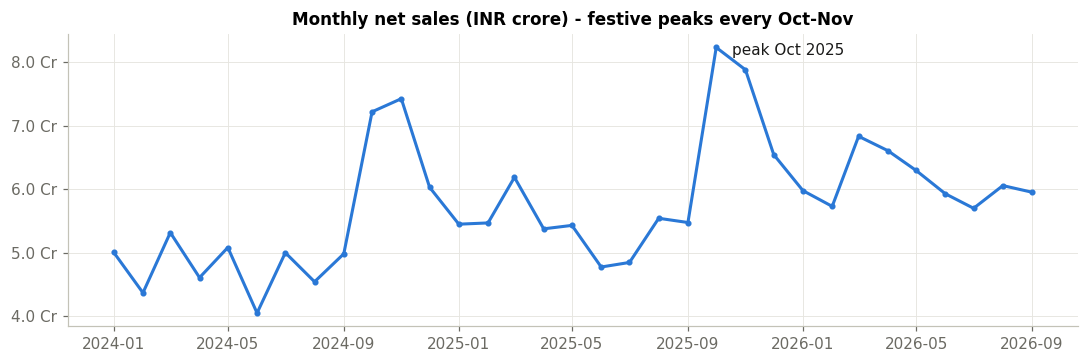

net sales by year (Cr): {2024: 63.7, 2025: 71.2, 2026: 55.1} | 2026 = Jan-Sep only


In [8]:
m = q('''SELECT date_trunc('month', order_date) AS month, SUM(net_sales_value) AS net_sales,
                SUM(quantity) FILTER (WHERE order_status <> 'Cancelled') AS demand, SUM(lost_qty) AS lost
         FROM fact_sales GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(m.month, m.net_sales, color=BLUE, marker="o", markersize=3)
ax.yaxis.set_major_formatter(inr_cr); ax.set_title("Monthly net sales (INR crore) - festive peaks every Oct-Nov")
pk = m.loc[m.net_sales.idxmax()]; ax.annotate(f"peak {pk.month:%b %Y}", (pk.month, pk.net_sales), xytext=(10, -5), textcoords="offset points", color=INK)
save(fig, "02_monthly_sales.png")
yr = m.assign(y=m.month.dt.year).groupby("y").net_sales.sum()
print("net sales by year (Cr):", (yr / 1e7).round(1).to_dict(), "| 2026 = Jan-Sep only")

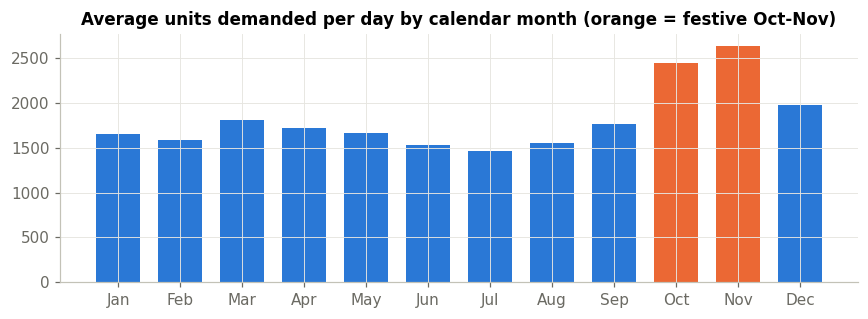

festive uplift vs other months: 52%


In [9]:
seas = q('''SELECT month(order_date) AS m, SUM(quantity) / COUNT(DISTINCT order_date) AS units_per_day
            FROM fact_sales WHERE order_status <> 'Cancelled' GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(seas.m, seas.units_per_day, color=[CAT[1] if x in (10, 11) else BLUE for x in seas.m], width=0.7)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Average units demanded per day by calendar month (orange = festive Oct-Nov)")
save(fig, "03_seasonality.png")
festive_uplift = seas.set_index("m").units_per_day.loc[[10, 11]].mean() / seas.set_index("m").units_per_day.drop([10, 11]).mean() - 1
print(f"festive uplift vs other months: {festive_uplift:.0%}")

## 5. Inventory trend by warehouse

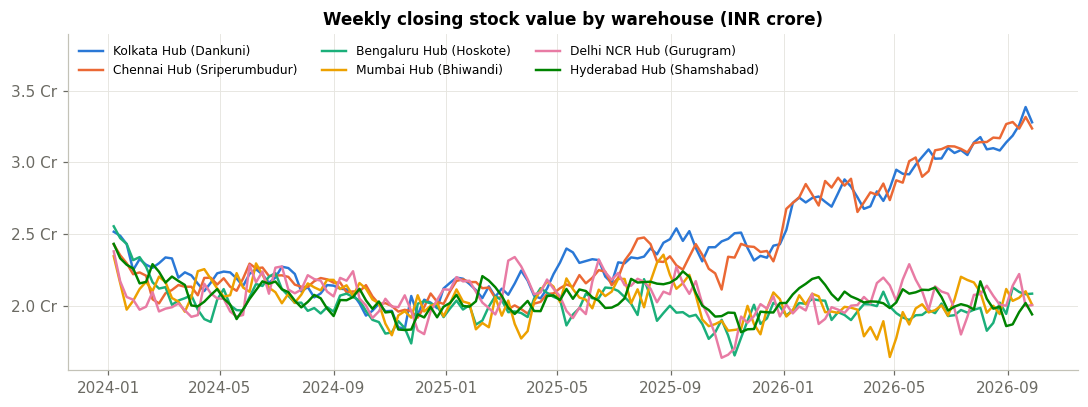

latest snapshot 2026-09-27 | stock value (Cr): {'Kolkata Hub (Dankuni)': 3.28, 'Chennai Hub (Sriperumbudur)': 3.24, 'Bengaluru Hub (Hoskote)': 2.09, 'Mumbai Hub (Bhiwandi)': 2.01, 'Delhi NCR Hub (Gurugram)': 2.01, 'Hyderabad Hub (Shamshabad)': 1.94}


In [10]:
inv = q('''SELECT i.snapshot_date, w.warehouse_name AS wh, SUM(i.stock_quantity * p.unit_cost) AS value
           FROM fact_inventory_snapshot i JOIN dim_product p USING (product_id) JOIN dim_warehouse w USING (warehouse_id)
           GROUP BY ALL ORDER BY 1''')
pv = inv.pivot(index="snapshot_date", columns="wh", values="value")
pv = pv[pv.iloc[-1].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, c in enumerate(pv.columns):
    ax.plot(pv.index, pv[c], color=CAT[i], label=c, linewidth=1.6)
ax.set_ylim(top=pv.max().max() * 1.15); ax.yaxis.set_major_formatter(inr_cr); ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper left")
ax.set_title("Weekly closing stock value by warehouse (INR crore)")
save(fig, "04_stock_value_by_warehouse.png")
latest = pv.iloc[-1].sort_values(ascending=False)
print("latest snapshot", pv.index[-1].date(), "| stock value (Cr):", (latest / 1e7).round(2).to_dict())

## 6. ABC (revenue) x XYZ (demand variability) - SQL Q04 / Q20

,abc_class,products,pct_products,net_sales,pct_revenue,best_decile,worst_decile
0,A,66,16.5,1.519154e+09,80.0,1,2
1,B,96,24.0,2.852109e+08,15.0,2,5
2,C,238,59.5,9.566294e+07,5.0,5,10


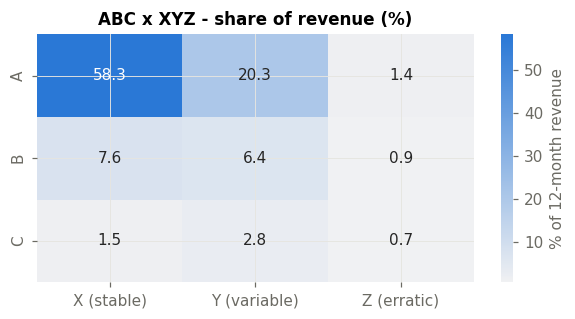

,abc_class,xyz_class,products,revenue_12m,pct_revenue,avg_cv
0,A,X (stable),37,450324916.0,58.3,0.35
1,A,Y (variable),22,156936488.0,20.3,0.63
2,A,Z (erratic),3,10491215.0,1.4,1.08
3,B,X (stable),45,59089733.0,7.6,0.35
4,B,Y (variable),40,49820310.0,6.4,0.65
5,B,Z (erratic),6,7070896.0,0.9,1.18
6,C,X (stable),53,11488171.0,1.5,0.40
7,C,Y (variable),144,21973842.0,2.8,0.74
8,C,Z (erratic),47,5686609.0,0.7,1.16


In [11]:
sql_text = (ROOT / "sql" / "03_analysis_queries.sql").read_text(encoding="utf-8")
parts = re.split(r"^-- (Q\d+): (.*)$", sql_text, flags=re.M)
QUERIES = {parts[i]: (parts[i + 1].strip(), re.sub(r"^--.*$", "", parts[i + 2], flags=re.M).strip().rstrip(";"))
           for i in range(1, len(parts), 3)}
run = lambda qid: q(QUERIES[qid][1])
display(run("Q04"))
abcxyz = run("Q20")
hm = abcxyz.pivot(index="abc_class", columns="xyz_class", values="pct_revenue").fillna(0)
fig, ax = plt.subplots(figsize=(5.5, 3))
sns.heatmap(hm, annot=True, fmt=".1f", cmap=sns.light_palette(BLUE, as_cmap=True), cbar_kws={"label": "% of 12-month revenue"}, ax=ax)
ax.set_title("ABC x XYZ - share of revenue (%)"); ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "05_abc_xyz.png")
abcxyz

## 7. Stockouts (Q05) and days of cover (Q08)

,product_id,product_name,main_supplier,stockout_rate_pct,lost_units,lost_sales_value,fill_rate_pct
0,P0007,Urban Paper S498,Ganesh Supply Chain LLP,43.0,15635.0,1165248.0,52.1
1,P0254,Agni Small Appliances M220,Unity Suppliers,33.3,10573.0,54342993.0,62.2
2,P0261,Nimbu Beverages L489,Ganesh Supply Chain LLP,22.1,2829.0,95538.0,63.1
3,P0042,Aarav Small Appliances F759,Unity Suppliers,21.6,2282.0,4994094.0,65.6
4,P0092,Saral Snacks T713,Unity Suppliers,20.4,1884.0,250946.0,69.4
5,P0241,Swift Hygiene E215,Ganesh Supply Chain LLP,19.1,7333.0,6804117.0,69.6
6,P0283,Kriti Desk Accessories G154,Ganesh Supply Chain LLP,17.4,3685.0,877407.0,71.8
7,P0240,Aarav Men S792,Ganesh Supply Chain LLP,15.2,2222.0,1208306.0,58.8
8,P0302,Kriti Writing B468,Ganesh Sourcing Pvt Ltd,15.0,2284.0,784782.0,71.6
9,P0394,Desi Power Tools A402,Ganesh Sourcing Pvt Ltd,14.7,2377.0,3403926.0,59.4


11 of the top-15 stockout products are in the embedded 'chronic stockout' answer key (12 products)


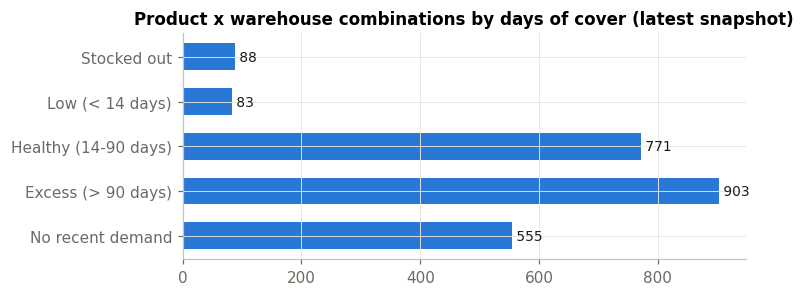

cover_band
Stocked out              88
Low (< 14 days)          83
Healthy (14-90 days)    771
Excess (> 90 days)      903
No recent demand        555
Name: count, dtype: int64

In [12]:
so = run("Q05")
display(so.head(10)[["product_id", "product_name", "main_supplier", "stockout_rate_pct", "lost_units", "lost_sales_value", "fill_rate_pct"]])
key = pd.read_csv(ROOT / "data" / "embedded_patterns_answer_key.csv")
chronic = set(key[key.Pattern == "Chronic stockout"].Product_ID)
print(f"{len(set(so.product_id) & chronic)} of the top-15 stockout products are in the embedded 'chronic stockout' answer key ({len(chronic)} products)")
cov = run("Q08")
band = cov.cover_band.value_counts()
fig, ax = plt.subplots(figsize=(7, 2.8))
order = ["Stocked out", "Low (< 14 days)", "Healthy (14-90 days)", "Excess (> 90 days)", "No recent demand"]
band = band.reindex(order).fillna(0)
ax.barh(band.index, band.values, color=BLUE, height=0.6); ax.invert_yaxis()
for y, v in enumerate(band.values): ax.text(v, y, f" {int(v)}", va="center", color=INK, fontsize=9)
ax.set_title("Product x warehouse combinations by days of cover (latest snapshot)")
save(fig, "06_days_of_cover.png")
band

## 8. Excess inventory (Q09) and dead stock (Q10)

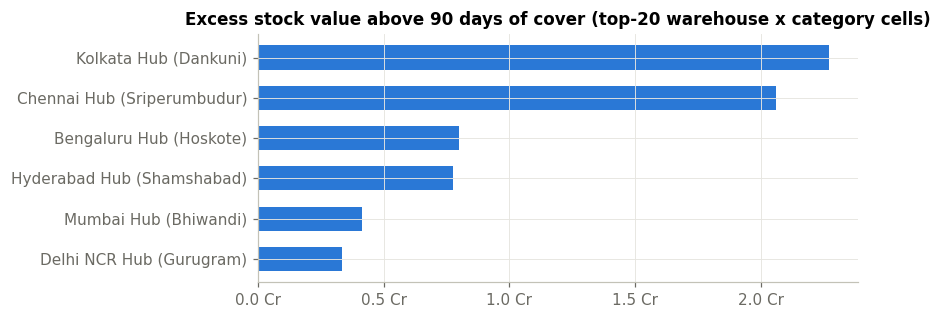

dead-stock rows: 335, value INR 3.53 Cr


,warehouse_name,category,excess_units,excess_value_inr,excess_holding_cost_per_year,excess_rank
0,Kolkata Hub (Dankuni),Home & Kitchen,4860.0,10597188.0,2119438.0,1
1,Chennai Hub (Sriperumbudur),Home & Kitchen,4359.0,10344533.0,2068907.0,2
2,Chennai Hub (Sriperumbudur),Electronics,1434.0,4264431.0,852886.0,3
3,Kolkata Hub (Dankuni),Furniture,690.0,4247701.0,849540.0,4
4,Kolkata Hub (Dankuni),Electronics,1575.0,4190154.0,838031.0,5
5,Chennai Hub (Sriperumbudur),Furniture,630.0,3908313.0,781663.0,6
6,Hyderabad Hub (Shamshabad),Electronics,1068.0,3429840.0,685968.0,7
7,Bengaluru Hub (Hoskote),Electronics,1054.0,3160909.0,632182.0,8


In [13]:
ex = run("Q09")
exw = ex.groupby("warehouse_name").excess_value_inr.sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(exw.index, exw.values, color=BLUE, height=0.6); ax.xaxis.set_major_formatter(inr_cr)
ax.set_title("Excess stock value above 90 days of cover (top-20 warehouse x category cells)")
save(fig, "07_excess_by_warehouse.png")
dead = run("Q10")
print(f"dead-stock rows: {len(dead)}, value INR {dead.filter(like='value').iloc[:,0].sum()/1e7:.2f} Cr")
display(ex.head(8))

## 9. Supplier performance (Q11, Q12)

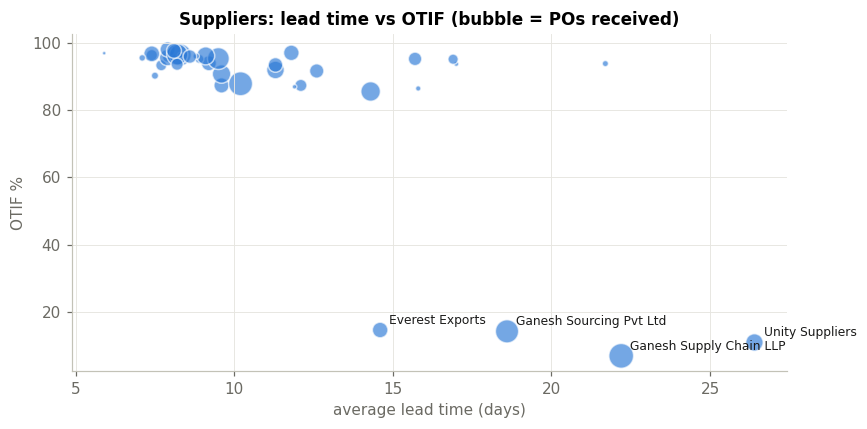

,supplier_name,rating,pos_received,avg_lead_time_days,lead_time_std_dev,avg_delay_days,on_time_pct,otif_pct
0,Unity Suppliers,2.6,780,26.4,17.2,12.5,16.2,10.9
1,Ganesh Supply Chain LLP,3.3,1580,22.2,14.8,12.2,10.6,6.9
2,Ganesh Sourcing Pvt Ltd,3.2,1390,18.6,11.7,7.8,19.6,14.2
3,Everest Exports,2.9,624,14.6,9.2,5.6,19.7,14.6
4,Prime Supply Chain LLP,4.4,595,9.6,3.7,-0.9,89.6,87.4
5,Sterling Traders,4.8,134,7.5,2.1,-0.9,92.5,90.3
6,Apex Enterprises,4.1,1478,10.2,3.7,-1.1,90.9,87.9
7,Galaxy Industries,4.8,317,7.7,3.8,-1.1,95.9,93.4


In [14]:
sup = run("Q11")
fig, ax = plt.subplots(figsize=(8, 4))
sc = ax.scatter(sup.avg_lead_time_days, sup.otif_pct, s=sup.pos_received / 6, color=BLUE, alpha=0.65, edgecolor="white", linewidth=1)
for _, r in sup.nlargest(4, "avg_delay_days").iterrows():
    ax.annotate(r.supplier_name, (r.avg_lead_time_days, r.otif_pct), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("average lead time (days)"); ax.set_ylabel("OTIF %"); ax.set_title("Suppliers: lead time vs OTIF (bubble = POs received)")
save(fig, "08_supplier_scatter.png")
sup.head(8)[["supplier_name", "rating", "pos_received", "avg_lead_time_days", "lead_time_std_dev", "avg_delay_days", "on_time_pct", "otif_pct"]]

## 10. Inventory turnover (Q13) and holding cost (Q14, Q21)

,category,cogs_12m,avg_inventory_value,inventory_turnover,days_inventory_outstanding,slowest_rank
0,Home & Kitchen,74815004.0,30571265.0,2.45,149.0,1
1,Hardware & Tools,28720012.0,8719950.0,3.29,111.0,2
2,Furniture,106582189.0,27927989.0,3.82,96.0,3
3,Apparel,65991010.0,14090076.0,4.68,78.0,4
4,Electronics,182277215.0,38870887.0,4.69,78.0,5
5,Personal Care,33708082.0,6735330.0,5.00,73.0,6
6,Grocery & FMCG,24674102.0,4640080.0,5.32,69.0,7
7,Office Supplies,26037471.0,3921395.0,6.64,55.0,8


,warehouse_name,avg_stock_value,carrying_cost_per_year,fixed_cost_per_year,total_cost_per_unit_shipped,network_carrying_cost
0,Chennai Hub (Sriperumbudur),28010313.0,5602063.0,31200000.0,540.93,27095395.0
1,Kolkata Hub (Dankuni),28011395.0,5602279.0,28800000.0,534.68,27095395.0
2,Hyderabad Hub (Shamshabad),20199085.0,4039817.0,32400000.0,448.33,27095395.0
3,Bengaluru Hub (Hoskote),19519684.0,3903937.0,38400000.0,434.96,27095395.0
4,Mumbai Hub (Bhiwandi),19649919.0,3929984.0,54000000.0,360.66,27095395.0
5,Delhi NCR Hub (Gurugram),20086576.0,4017315.0,45600000.0,339.84,27095395.0


,warehouse_name,stock_value,releasable_value,pct_releasable,holding_cost_saving_per_year,cumulative_saving
0,Kolkata Hub (Dankuni),32801216.0,18876763.0,57.5,3775353.0,3775353.0
1,Chennai Hub (Sriperumbudur),32371652.0,18296992.0,56.5,3659398.0,7434751.0
2,Bengaluru Hub (Hoskote),20851199.0,6175550.0,29.6,1235110.0,8669861.0
3,Hyderabad Hub (Shamshabad),19406720.0,5066843.0,26.1,1013369.0,9683230.0
4,Mumbai Hub (Bhiwandi),20081412.0,4227836.0,21.1,845567.0,10528797.0
5,Delhi NCR Hub (Gurugram),20051454.0,3851488.0,19.2,770298.0,11299095.0


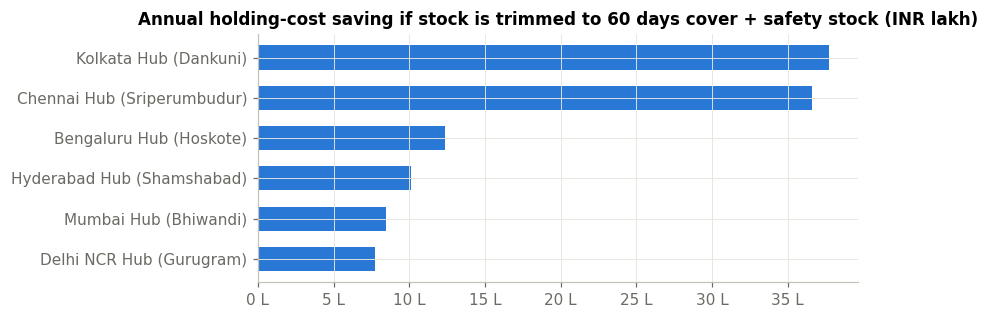

In [15]:
display(run("Q13"))
hc = run("Q14"); display(hc)
sav = run("Q21"); display(sav)
fig, ax = plt.subplots(figsize=(8, 3))
sv = sav.set_index("warehouse_name").holding_cost_saving_per_year.sort_values()
ax.barh(sv.index, sv.values, color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e5:,.0f} L"))
ax.set_title("Annual holding-cost saving if stock is trimmed to 60 days cover + safety stock (INR lakh)")
save(fig, "09_holding_cost_saving.png")

## 11. Reorder recommendations (Q15)

In [16]:
ro = run("Q15")
print(ro.priority.value_counts().sort_index().to_string())
print(f"suggested order value: INR {(ro.suggested_order_qty * ro.merge(con.execute('SELECT product_id, unit_cost FROM dim_product').df(), on='product_id').unit_cost).sum()/1e7:.2f} Cr")
ro.head(10)

priority
1 - Urgent (stocked out)             81
2 - High (below safety stock)       138
3 - Normal (below reorder point)    120
suggested order value: INR 1.10 Cr


,warehouse_name,product_id,product_name,category,available_stock,reorder_point,on_order,avg_daily_demand,suggested_order_qty,priority
0,Mumbai Hub (Bhiwandi),P0020,Urban Computer Peripherals K657,Electronics,0,88,114.0,7.09,287.0,1 - Urgent (stocked out)
1,Mumbai Hub (Bhiwandi),P0040,Indus Mobile Accessories C906,Electronics,0,25,37.0,1.01,31.0,1 - Urgent (stocked out)
2,Delhi NCR Hub (Gurugram),P0196,Mitra Smart Home A254,Electronics,0,86,137.0,5.71,172.0,1 - Urgent (stocked out)
3,Chennai Hub (Sriperumbudur),P0139,Pristine Tables R281,Furniture,0,28,0.0,0.57,50.0,1 - Urgent (stocked out)
4,Delhi NCR Hub (Gurugram),P0039,Ruby Mobile Accessories S544,Electronics,0,74,98.0,2.23,68.0,1 - Urgent (stocked out)
5,Delhi NCR Hub (Gurugram),P0094,Saral Storage D289,Home & Kitchen,0,31,38.0,2.26,83.0,1 - Urgent (stocked out)
6,Mumbai Hub (Bhiwandi),P0294,Indus Computer Peripherals M684,Electronics,0,96,126.0,5.54,197.0,1 - Urgent (stocked out)
7,Delhi NCR Hub (Gurugram),P0176,Urban Smart Home G506,Electronics,0,24,28.0,0.58,25.0,1 - Urgent (stocked out)
8,Delhi NCR Hub (Gurugram),P0230,Orbit Mobile Accessories R198,Electronics,0,31,34.0,1.92,92.0,1 - Urgent (stocked out)
9,Delhi NCR Hub (Gurugram),P0241,Swift Hygiene E215,Personal Care,0,13,0.0,5.93,215.0,1 - Urgent (stocked out)


## 12. Run every SQL query in `sql/03_analysis_queries.sql`

In [17]:
res = []
for qid, (title, body) in QUERIES.items():
    try:
        n = len(q(body)); res.append((qid, "OK", n, title[:80]))
    except Exception as e:
        res.append((qid, "FAIL", 0, str(e)[:80]))
res = pd.DataFrame(res, columns=["query", "status", "rows", "title"])
print(f"{(res.status == 'OK').sum()} / {len(res)} queries passed")
res

21 / 21 queries passed


,query,status,rows,title
0,Q01,OK,3,Warehouse row counts and date coverage (data h...
1,Q02,OK,33,Monthly sales trend with MoM growth (LAG) and ...
2,Q03,OK,20,Which products have the highest demand? Top 20...
3,Q04,OK,3,ABC classification - cumulative revenue share ...
4,Q05,OK,15,Which products frequently go out of stock? Sto...
5,Q06,OK,6,Which warehouse holds the most inventory? Late...
6,Q07,OK,198,Monthly inventory value by warehouse (month-en...
7,Q08,OK,2400,Days of cover per product x warehouse (latest ...
8,Q09,OK,20,Where is excess inventory accumulating? Value ...
9,Q10,OK,335,Dead stock - items with stock on hand but no s...


## 13. Key numbers (used in the findings and README)

In [18]:
s_ok = q("SELECT SUM(net_sales_value) ns, SUM(quantity) FILTER (WHERE order_status<>'Cancelled') dem, SUM(lost_qty) lost FROM fact_sales").iloc[0]
KEY = {
    "net_sales_cr": round(s_ok.ns / 1e7, 1),
    "fill_rate_pct": round(100 * (1 - s_ok.lost / s_ok.dem), 1),
    "festive_uplift_pct": round(100 * festive_uplift, 0),
    "top_warehouse": latest.index[0], "top_warehouse_value_cr": round(latest.iloc[0] / 1e7, 2),
    "network_stock_cr": round(latest.sum() / 1e7, 2),
    "worst_stockout": f"{so.iloc[0].product_name} ({so.iloc[0].product_id}) {so.iloc[0].stockout_rate_pct}% of weeks",
    "slowest_supplier": f"{sup.iloc[0].supplier_name} avg {sup.iloc[0].avg_lead_time_days} d, OTIF {sup.iloc[0].otif_pct}%",
    "best_supplier_otif": float(sup.otif_pct.max()),
    "a_products": int(run("Q04").iloc[0].products),
    "excess_top_cell": f"{ex.iloc[0].warehouse_name} / {ex.iloc[0].category} INR {ex.iloc[0].excess_value_inr/1e7:.2f} Cr",
    "carrying_cost_cr": round(hc.network_carrying_cost.iloc[0] / 1e7, 2),
    "saving_60d_cr": round(sav.holding_cost_saving_per_year.sum() / 1e7, 2),
    "releasable_cr": round(sav.releasable_value.sum() / 1e7, 2),
    "restock_rows": len(ro), "restock_urgent": int((ro.priority.str.startswith("1")).sum()),
    "slowest_category": run("Q13").iloc[0].category, "slowest_dio": float(run("Q13").iloc[0].days_inventory_outstanding),
}
con.close()
KEY

{'net_sales_cr': np.float64(190.0),
 'fill_rate_pct': np.float64(87.9),
 'festive_uplift_pct': np.float64(52.0),
 'top_warehouse': 'Kolkata Hub (Dankuni)',
 'top_warehouse_value_cr': np.float64(3.28),
 'network_stock_cr': np.float64(14.56),
 'worst_stockout': 'Urban Paper S498 (P0007) 43.0% of weeks',
 'slowest_supplier': 'Unity Suppliers avg 26.4 d, OTIF 10.9%',
 'best_supplier_otif': 98.1,
 'a_products': 66,
 'excess_top_cell': 'Kolkata Hub (Dankuni) / Home & Kitchen INR 1.06 Cr',
 'carrying_cost_cr': np.float64(2.71),
 'saving_60d_cr': np.float64(1.13),
 'releasable_cr': np.float64(5.65),
 'restock_rows': 339,
 'restock_urgent': 81,
 'slowest_category': 'Home & Kitchen',
 'slowest_dio': 149.0}

## 14. Findings (synthetic data)

1. **Demand** - INR 190 Cr net sales over Jan 2024 - Sep 2026 (63.7 Cr in 2024, 71.2 Cr in 2025, 55.1 Cr in Jan-Sep 2026). Demand is strongly seasonal: average units per day in the Oct-Nov festive months are ~52% above other months. 66 products (16.5%) make 80% of revenue (A class); 58% of 12-month revenue comes from A-class products with stable (X) demand.
2. **Out-of-stock products** - Urban Paper S498 (P0007) was out of stock in 43% of weekly snapshots (fill rate 52%), followed by Agni Small Appliances M220 (P0254, 33%, INR 5.4 Cr lost sales). 11 of the top-15 stockout products are the embedded 'chronic stockout' items - most are sourced from Unity Suppliers or Ganesh Supply Chain LLP, the two slowest suppliers. Overall fill rate is 87.9%.
3. **Warehouse with the most inventory** - Kolkata Hub (Dankuni) holds the most stock by value (INR 3.28 Cr, 26.1k units) closely followed by Chennai Hub (Sriperumbudur) at 3.24 Cr; both rose from ~2.2 Cr in 2024 while the other four hubs stayed flat at ~2 Cr. Mumbai (Bhiwandi) is the most utilised hub (89.6% of capacity).
4. **Slow suppliers** - Unity Suppliers (avg lead time 26.4 days, std dev 17.2, OTIF 10.9%) and Ganesh Supply Chain LLP (22.2 days, OTIF 6.9%) are the slowest and least reliable; Ganesh Sourcing Pvt Ltd and Everest Exports follow. Good suppliers deliver in 7-10 days with OTIF near 90%.
5. **Excess inventory** - Excess stock (above 90 days of cover) concentrates in Kolkata and Chennai, mainly Home & Kitchen (INR 1.06 Cr and 1.03 Cr), Electronics and Furniture. 335 product x warehouse rows are dead stock (no sale for 180+ days) worth INR 3.53 Cr. Home & Kitchen turns only 2.45x a year (149 days inventory outstanding).
6. **Holding cost** - At a 20%/yr carrying rate the network spends ~INR 2.71 Cr a year to hold stock (plus warehouse fixed costs). Trimming every product x warehouse to 60 days of cover + safety stock would release INR 5.65 Cr of inventory and save ~INR 1.13 Cr a year in holding cost - two thirds of it in Kolkata and Chennai.
7. **Restocking** - 339 product x warehouse rows are at or below their reorder point at the latest snapshot: 81 urgent (already stocked out), 138 below safety stock and 120 below reorder point; the suggested orders are worth ~INR 1.10 Cr.

**Recommendations:** (1) dual-source or re-negotiate the chronic-stockout items currently bought from Unity Suppliers / Ganesh Supply Chain LLP and add their lead-time variability to safety stock; (2) stop replenishing obsolete SKUs and liquidate / transfer the dead stock in Kolkata and Chennai; (3) set reorder points by ABC-XYZ class (higher service level for AX/AY, lower for C); (4) build festive (Oct-Nov) stock from August instead of reacting in October; (5) review the restock list weekly, urgent rows first.

*All figures come from the synthetic dataset and the 20%/yr holding-cost assumption (capital 10% + storage/handling 5% +
obsolescence/shrinkage 5%); they show the method, not a real company's performance.*